# Supplementary information for “Dataset distillation for optical neural networks”

Run each section in order to recalculate its results from the supplied data.



## Supplementary Note 1. Experimental characterization of the reservoir-type ONN


In [1]:
from pathlib import Path
from utils.datasets import flat_result_path, flat_result_directory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.io import loadmat
from IPython.display import display
from utils.optical_characterization import (
    analyze_tm_distribution, pearson_rows,
)

SAVE_FIGURES = False  # Enable only when exporting figures.
SAVE_DETAILS = False  # Optional per-run supports and diagnostics.
ROOT = Path.cwd()
CHARACTERIZATION_DATA = ROOT / 'experimental_results/optical_characterization'
CHARACTERIZATION_ANALYSIS = ROOT / 'results/experimental/optical_characterization'
SI_FIGURES = ROOT / 'results/SI/figures'
for folder in (CHARACTERIZATION_ANALYSIS, SI_FIGURES):
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.linewidth': 0.7, 'svg.fonttype': 'none'})

### TM statistics — Supplementary Figure 2a

Fit Gaussian distributions to the real and imaginary components of the measured 784 × 1024 TM.

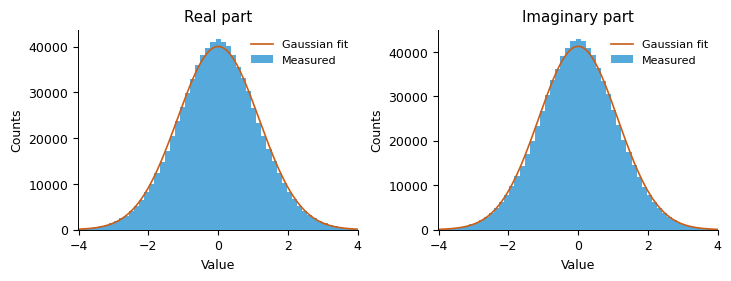

In [2]:
tm_distribution = analyze_tm_distribution(CHARACTERIZATION_DATA / 'exp_TM.mat')
np.savez_compressed(flat_result_path(CHARACTERIZATION_ANALYSIS / 'tm_distribution.npz'), **tm_distribution)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), constrained_layout=True)
edges = tm_distribution['bin_edges']
centers, width = (edges[:-1] + edges[1:]) / 2, edges[1] - edges[0]
curve_x = np.linspace(edges[0], edges[-1], 500)
for ax, component, title in zip(axes, ['real', 'imag'], ['Real part', 'Imaginary part']):
    ax.bar(centers, tm_distribution[f'{component}_counts'], width=width,
           color=(0.337, 0.667, 0.859), label='Measured')
    expected = tm_distribution[f'{component}_sample_count'] * width * norm.pdf(
        curve_x, tm_distribution[f'{component}_mu'], tm_distribution[f'{component}_sigma'])
    ax.plot(curve_x, expected, color=(0.796, 0.365, 0.090), lw=1.2, label='Gaussian fit')
    ax.set(title=title, xlabel='Value', ylabel='Counts', xlim=(edges[0], edges[-1]))
    ax.legend(frameon=False, fontsize=8)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'measured_tm_gaussian.png'), dpi=200)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'measured_tm_gaussian.svg'))
plt.show()

### Speckle stability — Supplementary Figure 2b

In [3]:
measured = loadmat(CHARACTERIZATION_DATA / 'speckle_stability.mat', squeeze_me=True)
intensity = measured['intensity']
elapsed_s = measured['elapsed_s']
assert intensity.shape == (12728, 32 * 32)
assert elapsed_s.shape == (len(intensity),) and np.all(np.diff(elapsed_s) > 0)

correlation = pearson_rows(intensity, np.broadcast_to(intensity[:1], intensity.shape))
time_minutes = elapsed_s / 60
# Preserve acquisition times, including gaps; the final acquisition may slightly exceed 150 min.
bin_index = np.clip((time_minutes // 5).astype(int), 0, 29)
bin_time = np.array([time_minutes[bin_index == i].mean() for i in range(30)])
bin_mean = np.array([correlation[bin_index == i].mean() for i in range(30)])
first_2h_mean = correlation[time_minutes <= 120].mean()
full_period_mean = correlation.mean()
np.savez_compressed(
    flat_result_path(CHARACTERIZATION_ANALYSIS / 'speckle_stability.npz'),
    time_minutes=time_minutes, correlation=correlation,
    bin_time_minutes=bin_time, bin_mean_correlation=bin_mean, bin_minutes=5,
    mean_correlation=full_period_mean, first_2h_mean_correlation=first_2h_mean,
    retained_frame_count=len(intensity),
)
display(pd.DataFrame({
    'Period': ['First 2 h', 'Full 2.5 h'],
    'Mean Pearson correlation': [first_2h_mean, full_period_mean],
}).style.hide(axis='index').format({'Mean Pearson correlation': '{:.4f}'}))

Period,Mean Pearson correlation
First 2 h,0.9936
Full 2.5 h,0.9906


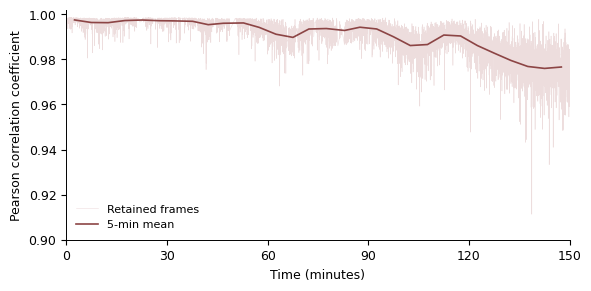

In [4]:
fig, ax = plt.subplots(figsize=(5.8, 2.8), constrained_layout=True)
ax.plot(time_minutes, correlation, color=(0.757, 0.522, 0.525), lw=0.4, alpha=0.28, label='Retained frames')
ax.plot(bin_time, bin_mean, color=(0.549, 0.271, 0.271), lw=1.2, label='5-min mean')
ax.set(xlabel='Time (minutes)', ylabel='Pearson correlation coefficient',
       xlim=(0, 150), ylim=(0.90, 1.002), xticks=np.arange(0, 151, 30))
ax.legend(frameon=False, loc='lower left', fontsize=8)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'speckle_stability.png'), dpi=200)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'speckle_stability.svg'))
plt.show()

### Forward-model agreement — Supplementary Note 1


In [5]:
tm = loadmat(CHARACTERIZATION_DATA / 'exp_TM.mat')['T'].astype(np.complex128)
validation = loadmat(CHARACTERIZATION_DATA / 'Forward_model_validation_speckle.mat')
x = validation['validation_x'].astype(np.float64)
measured = validation['validation_measured_reference_off'].astype(np.float64)
predicted = np.abs(np.exp(1j * np.pi * x) @ tm) ** 2
correlation_per_input = pearson_rows(predicted, measured)

tm_validation = {
    'validation_x': x, 'measured': measured, 'predicted': predicted,
    'correlation_per_input': correlation_per_input,
    'mean_correlation': correlation_per_input.mean(),
    'median_correlation': np.median(correlation_per_input),
}
np.savez_compressed(flat_result_path(CHARACTERIZATION_ANALYSIS / 'tm_validation.npz'), **tm_validation)
print(f"Mean Pearson correlation (32 inputs): {tm_validation['mean_correlation']:.4f}")

Mean Pearson correlation (32 inputs): 0.9564


## Supplementary Note 2. Implementation details of dataset distillation for the reservoir-type ONN

See [utils/distillation.py](utils/distillation.py), [utils/reservoir_onn.py](utils/reservoir_onn.py) and [utils/evaluation.py](utils/evaluation.py) for the shared implementation. Task-specific preprocessing and hyperparameters are provided in the Exp1–Exp3 notebooks.


## Supplementary Note 3. Ensemble versus model-specific dataset distillation

Reproduce Supplementary Figures 3 and 4 in order. Reservoir distillation is computed here. Physical accuracies are recalculated from
measured speckles and the targets deployed during acquisition.

In [6]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from utils.datasets import load_fmnist, save_npz
from utils.tm_specific import load_measured_tm, distill_measured_tm, evaluate_measured_tm
from utils.supplementary_analysis import (
    training_tm_summary, analyze_tm_specific_experiment, analyze_tm_specific_controls,
)

ROOT = Path.cwd()
SI_SIMULATION = ROOT / 'results/SI'
SI_ANALYSIS = ROOT / 'results/experimental/si'
SI_FIGURES = ROOT / 'results/SI/figures'
for folder in (SI_SIMULATION, SI_ANALYSIS, SI_FIGURES):
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda:1' if torch.cuda.device_count() > 1 else ('cuda:0' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
data = load_fmnist(ROOT / 'dataset', device=DEVICE, download=True)
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

### Training TM count — Supplementary Figure 3a


In [7]:
TRAIN_TM_COUNTS = [1, 2, 5, 10, 15, 20, 30, 40, 50, 75, 100]
train_tm_path = SI_SIMULATION / 'training_tm_ensemble.npz'
import torch
from utils.datasets import load_fmnist
from utils.distillation import DistillationConfig, distill_coreset
from utils.evaluation import evaluate_coreset
from utils.reservoir_onn import set_seed, tm_ensemble

device = 'cuda:1' if torch.cuda.device_count() > 1 else (
    'cuda:0' if torch.cuda.is_available() else 'cpu')
sweep_data = load_fmnist(ROOT / 'dataset', device=device, download=True)
accuracy = np.empty((len(TRAIN_TM_COUNTS), 5, 100), dtype=np.float32)
losses = np.empty((len(TRAIN_TM_COUNTS), 5, 700), dtype=np.float32)
images = np.empty((len(TRAIN_TM_COUNTS), 5, 10, 784), dtype=np.float32)
labels = np.empty((len(TRAIN_TM_COUNTS), 5, 10, 10), dtype=np.float32)
temperatures = np.empty((len(TRAIN_TM_COUNTS), 5), dtype=np.float32)
train_seeds, unseen_seeds = [], []
for rep in range(5):
    set_seed(2025+rep)
    train_seeds.append(np.arange(1000+1000*rep, 1100+1000*rep))
    unseen_seeds.append(np.arange(200000+1000*rep, 200100+1000*rep))
    training_tms = tm_ensemble(784, 1024, train_seeds[-1], device)
    unseen_tms = tm_ensemble(784, 1024, unseen_seeds[-1], device)
    config = DistillationConfig(images_per_class=1, ridge_lambda=0.1,
        steps=700, target_batch_size=1024, tms_per_step=4,
        coreset_seed=2025+rep, batch_seed=9025+rep, eval_every=0)
    for index, count in enumerate(TRAIN_TM_COUNTS):
        result = distill_coreset(sweep_data['x_train'], sweep_data['y_train'], training_tms[:count], config)
        evaluation = evaluate_coreset(result.x_coreset, result.y_coreset,
            sweep_data['x_test'], sweep_data['y_test'], unseen_tms, config.ridge_lambda)
        accuracy[index, rep] = evaluation['accuracy_per_tm']
        losses[index, rep] = result.loss_history
        images[index, rep] = result.x_coreset.cpu().numpy()
        labels[index, rep] = result.y_coreset.cpu().numpy()
        temperatures[index, rep] = result.final_temperature
    del training_tms, unseen_tms
save_npz(train_tm_path, {'train_tm_counts': TRAIN_TM_COUNTS,
    'accuracy_per_tm': accuracy, 'accuracy_mean_per_repetition': accuracy.mean(axis=2),
    'loss_history': losses, 'x_coreset': images, 'y_coreset': labels,
    'final_temperature': temperatures, 'train_tm_seeds': np.asarray(train_seeds),
    'unseen_tm_seeds': np.asarray(unseen_seeds)}, config={
        'repetitions': 5, 'unseen_tms_per_repetition': 100, 'steps': 700})

training_tms_result = training_tm_summary(train_tm_path)
train_tm_table = pd.DataFrame({
    'Training TMs': training_tms_result['train_tm_counts'],
    'Mean accuracy (%)': 100 * training_tms_result['mean'],
    'SD (%)': 100 * training_tms_result['std'],
})
train_tm_table.to_csv(flat_result_path(SI_ANALYSIS / 'training_tm_summary.csv'), index=False)

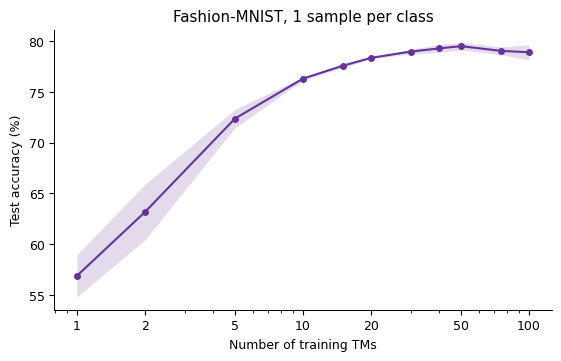

In [8]:
counts = training_tms_result['train_tm_counts']
mean, sd = 100 * training_tms_result['mean'], 100 * training_tms_result['std']
fig, ax = plt.subplots(figsize=(5.5, 3.5), constrained_layout=True)
ax.fill_between(counts, mean - sd, mean + sd, color='#663399', alpha=0.18, linewidth=0)
ax.plot(counts, mean, color='#663399', marker='o', lw=1.5, ms=4)
ax.set_xscale('log')
ax.set_xticks([1, 2, 5, 10, 20, 50, 100], labels=['1', '2', '5', '10', '20', '50', '100'])
ax.set(xlabel='Number of training TMs', ylabel='Test accuracy (%)',
       title='Fashion-MNIST, 1 sample per class')
ax.spines[['top', 'right']].set_visible(False)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'fmnist_training_tms.png'), dpi=200)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'fmnist_training_tms.svg'))
plt.show()

### TM-specific distillation — training curve and Supplementary Figure 3b


In [9]:
physical_path = ROOT / 'experimental_results/fmnist/tm_specific/Fmnist_tm_specific_speckle.mat'
tm_specific = analyze_tm_specific_experiment(physical_path, include_simulation=False)
tm_references = analyze_tm_specific_controls(ROOT / 'experimental_results/fmnist/figure2', channel_seed=17)
save_npz(SI_ANALYSIS / 'tm_specific_controls.npz', {
    'ensemble_accuracy': tm_references['tm_ensemble']['accuracy'],
    'random_accuracy': tm_references['random']['accuracy'],
    'source_files': tm_references['source_files'],
    'source_reps': tm_references['source_reps'],
    'acquisition_ids': tm_references['acquisition_ids']}, config={
        'channel_seed': 17, 'summary': 'pooled mean and sample SD across 18 readouts'})
tm_references['full_training'] = {}
measured_tm = load_measured_tm(ROOT / 'experimental_results/fmnist/tm_specific/measured_TM.mat', DEVICE)
measured_runs = []
deterministic_before = torch.are_deterministic_algorithms_enabled()
torch.use_deterministic_algorithms(True)
try:
    for seed in range(5):
        run = distill_measured_tm(data, measured_tm, seed, steps=1500,
                                 batch_size=128, ridge_lambda=.01, batch_seed=7)
        save_npz(SI_SIMULATION / f'tm_specific/seed{seed}.npz', run,
            config={'steps': 1500, 'batch_size': 128, 'ridge_lambda': .01,
                    'seed': seed, 'batch_seed': 7, 'model': 'measured T only'})
        measured_runs.append(run)
    tm_specific['simulation_accuracy_history'] = np.stack([r['accuracy_history'] for r in measured_runs])
    tm_specific['simulation_accuracy'] = tm_specific['simulation_accuracy_history'][:, -1]
    tm_specific['snapshot_steps'] = measured_runs[0]['snapshot_steps']
    full_score = evaluate_measured_tm(x_train, F.one_hot(y_train, 10).float(),
                                     x_test, y_test, measured_tm, .01, 1.)
    tm_references['full_training']['mean_percent'] = 100*full_score
finally:
    torch.use_deterministic_algorithms(deterministic_before)
del measured_tm, measured_runs
save_npz(SI_ANALYSIS / 'tm_specific_experiment.npz', tm_specific, config={
    'physical_readout_uses_deployed_targets': True, 'shared_physical_acquisition': True})
pd.DataFrame({
    'Training seed': tm_specific['training_seeds'],
    'Simulation accuracy (%)': 100 * tm_specific['simulation_accuracy'],
    'Experiment accuracy (%)': 100 * tm_specific['experimental_accuracy'],
}).to_csv(flat_result_path(SI_ANALYSIS / 'tm_specific_seeds.csv'), index=False)
print('TM-specific analysis complete.')

TM-specific analysis complete.


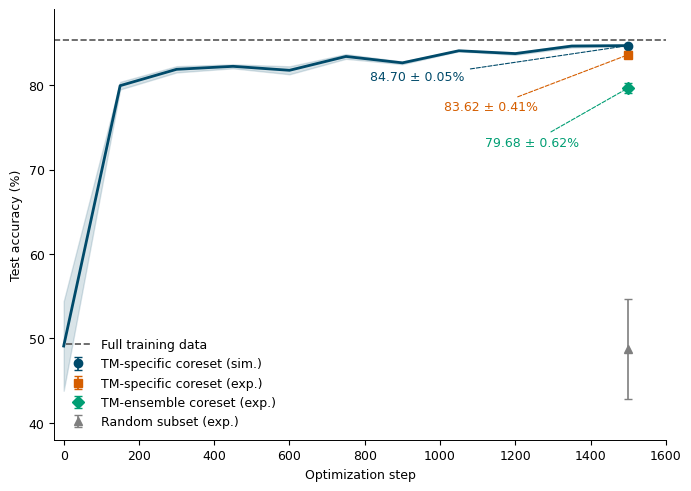

In [10]:
steps = tm_specific['snapshot_steps']
history = 100 * tm_specific['simulation_accuracy_history']
mean, sd = history.mean(axis=0), history.std(axis=0, ddof=1)
experiment = 100 * tm_specific['experimental_accuracy']
points = [
    (mean[-1], sd[-1], 'o', '#004A6A', 'TM-specific coreset (sim.)'),
    (experiment.mean(), experiment.std(ddof=1), 's', '#D55E00', 'TM-specific coreset (exp.)'),
    (tm_references['tm_ensemble']['mean_percent'], tm_references['tm_ensemble']['sd_percent'],
     'D', '#009E73', 'TM-ensemble coreset (exp.)'),
    (tm_references['random']['mean_percent'], tm_references['random']['sd_percent'],
     '^', '#7F7F7F', 'Random subset (exp.)'),
]
fig, ax = plt.subplots(figsize=(6.8, 4.8), constrained_layout=True)
ax.fill_between(steps, mean - sd, mean + sd, color='#004A6A', alpha=0.15)
ax.plot(steps, mean, color='#004A6A', lw=2)
ax.axhline(tm_references['full_training']['mean_percent'], color='#555555', ls='--',
           lw=1.2, label='Full training data')
for value, error, marker, color, label in points:
    ax.errorbar(steps[-1], value, yerr=error, fmt=marker, color=color,
                ms=6, capsize=3, lw=1.2, label=label)
for (value, error, _, color, _), xytext in zip(points[:3], [(815, 80.6), (1010, 77), (1120, 72.8)]):
    ax.annotate(f'{value:.2f} ± {error:.2f}%', xy=(steps[-1], value), xytext=xytext,
                color=color, fontsize=9,
                arrowprops={'arrowstyle': '-', 'color': color, 'linestyle': '--', 'linewidth': 0.8})
ax.set(xlabel='Optimization step', ylabel='Test accuracy (%)', xlim=(-25, 1600), ylim=(38, 89))
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left', fontsize=9)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'fmnist_tm_specific.png'), dpi=200)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'fmnist_tm_specific.svg'))
plt.show()

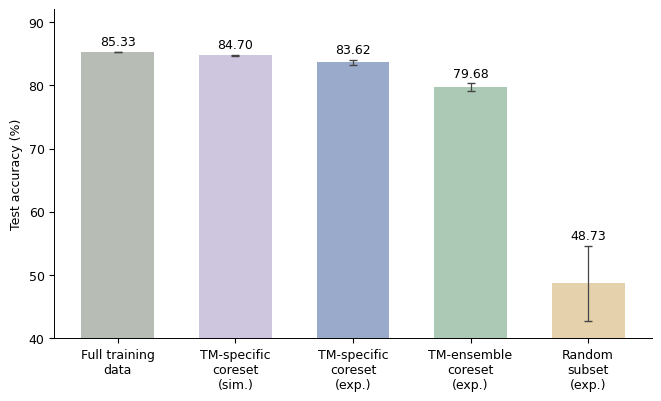

In [11]:
means = np.array([tm_references['full_training']['mean_percent']] + [point[0] for point in points])
errors = np.array([0.0] + [point[1] for point in points])
labels = ['Full training\ndata', 'TM-specific\ncoreset\n(sim.)', 'TM-specific\ncoreset\n(exp.)',
          'TM-ensemble\ncoreset\n(exp.)', 'Random\nsubset\n(exp.)']
colors = [(0.718, 0.741, 0.710), (0.808, 0.773, 0.871), (0.600, 0.667, 0.796),
          (0.671, 0.788, 0.706), (0.898, 0.824, 0.675)]
fig, ax = plt.subplots(figsize=(6.5, 3.9), constrained_layout=True)
ax.bar(np.arange(5), means, width=0.62, color=colors, yerr=errors,
       error_kw={'ecolor': '#444444', 'capsize': 3, 'lw': 0.9})
for i, (value, error) in enumerate(zip(means, errors)):
    ax.text(i, value + error + 1.0, f'{value:.2f}', ha='center', fontsize=9)
ax.set(xticks=np.arange(5), xticklabels=labels, ylabel='Test accuracy (%)', ylim=(40, 92))
ax.spines[['top', 'right']].set_visible(False)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'fmnist_tm_specific_comparison.png'), dpi=200)
if SAVE_FIGURES:
    fig.savefig(flat_result_path(SI_FIGURES / 'fmnist_tm_specific_comparison.svg'))
plt.show()
pd.DataFrame({'Condition': [s.replace('\n', ' ') for s in labels],
              'Mean accuracy (%)': means, 'SD (%)': [np.nan, *errors[1:]]}).to_csv(
    flat_result_path(SI_ANALYSIS / 'tm_specific_comparison.csv'), index=False)

### MZI mesh: device-specific transfer — Supplementary Figure 4

See [Exp4_MZI_Adaptive_Retraining.ipynb](Exp4_MZI_Adaptive_Retraining.ipynb), section 7, for device-specific distillation, transfer evaluation and the figure.


## Supplementary Note 4. Dataset distillation and adaptive retraining of the programmable ONN

See [Exp4_MZI_Adaptive_Retraining.ipynb](Exp4_MZI_Adaptive_Retraining.ipynb), section 5, for Supplementary Figure 7a–d: distillation convergence, update-rule ablations, sample-count ablations and synthetic-input examples.


## Supplementary Note 5. Resilience of synthetic coresets to out-of-distribution model mismatch

### A. Experimental optical imperfections in the reservoir-type ONN


In [28]:
from pathlib import Path
from dataclasses import asdict
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from utils.datasets import load_fmnist, load_npz, save_npz, save_json, random_coreset
from utils.distillation import DistillationConfig, distill_coreset
from utils.reservoir_onn import random_tm, tm_ensemble, fit_ridge
from utils.model_mismatch import optical_error_maps, mismatch_intensity, feature_deformation

RM_ROOT = Path.cwd()
RM_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
RM_RETRAIN_SUPPORTS = False  # True: repeat Exp1 distillation; missing supports are always trained.
RM_OUTPUT = RM_ROOT / 'results/SI/reservoir_mismatch'
RM_INPUTS = RM_ROOT / 'results/simulation/fmnist/sweep'
RM_FIGURES = RM_ROOT / 'results/SI/figures'
for folder in (RM_OUTPUT, RM_FIGURES):
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
RM_IPCS = [1, 2, 5]
RM_REPETITIONS, RM_TM_COUNT, RM_CORRELATION_INPUTS = 20, 50, 2000
RM_STEPS, RM_QUERY_BATCH, RM_TMS_PER_STEP = 700, 1024, 4
RM_LAMBDAS = {'coreset': {1: 0.1, 2: 0.1, 5: 0.01},
              'random': {1: 10.0, 2: 0.01, 5: 1.0}}
rm_data = load_fmnist(RM_ROOT / 'dataset', device=RM_DEVICE, download=True)
rm_test = rm_data['x_test'].cpu().numpy()
rm_labels = rm_data['y_test']
rm_test_seeds = np.stack([9000 + 1000*r + np.arange(RM_TM_COUNT)
                          for r in range(RM_REPETITIONS)])
rm_supports, rm_results = {}, {}

#### Ideal-model coresets and random subsets


In [29]:
for rep in range(RM_REPETITIONS):
    train_seeds = 1000 + 1000*rep + np.arange(RM_TM_COUNT)
    train_tms = None
    for ipc in RM_IPCS:
        cfg = DistillationConfig(images_per_class=ipc, ridge_lambda=RM_LAMBDAS['coreset'][ipc],
            steps=RM_STEPS, target_batch_size=RM_QUERY_BATCH, tms_per_step=RM_TMS_PER_STEP,
            coreset_seed=2025+rep, batch_seed=9025+rep)
        path = RM_INPUTS / f'ipc{ipc}_rep{rep}.npz'
        if not RM_RETRAIN_SUPPORTS and flat_result_path(path).exists():
            saved = load_npz(path)
            recorded = json.loads(str(saved['config_json']))['distillation']
            expected = asdict(cfg)
            assert all(recorded[k] == expected[k] for k in recorded), path
            x, y = saved['synthetic_images'], saved['synthetic_labels']
        else:
            if train_tms is None:
                train_tms = tm_ensemble(784, 1024, train_seeds, RM_DEVICE)
            trained = distill_coreset(rm_data['x_train'], rm_data['y_train'], train_tms, cfg)
            x, y = trained.x_coreset.cpu().numpy(), trained.y_coreset.cpu().numpy()
            save_npz(RM_OUTPUT / 'supports' / path.name,
                {'synthetic_images': x, 'synthetic_labels': y, 'loss': trained.loss_history,
                 'train_tm_seeds': train_seeds, 'test_tm_seeds': rm_test_seeds[rep]},
                config={'distillation': asdict(cfg)})
        rm_supports[rep, ipc, 'coreset'] = (x, y)
        # The same class-balanced random subsets and seeds as Exp1.
        xr, yr, _, _ = random_coreset(rm_data['x_train'], rm_data['y_train'], ipc, 22025+rep)
        rm_supports[rep, ipc, 'random'] = (xr.cpu().numpy(), yr.cpu().numpy())
    del train_tms
save_json(RM_OUTPUT / 'protocol.json', {
    'repetitions': RM_REPETITIONS, 'tms_per_repetition': RM_TM_COUNT, 'ipc_values': RM_IPCS,
    'training_steps': RM_STEPS, 'lambda': RM_LAMBDAS, 'quantization': 'none',
    'correlation_inputs': min(RM_CORRELATION_INPUTS, len(rm_test)),
    'accuracy_error_bars': 'Sample SD of repetition means; each mean averages 50 TMs.',
    'readout': 'Float32 primal ridge, no intercept; shared maximum of support/test intensity.',
    'error_maps': 'One fixed realization per repetition, shared by all TMs and methods.',
})
print('Ideal-model supports complete.')

Ideal-model supports complete.


#### Evaluation shared by the four error models


In [30]:
@torch.inference_mode()
def rm_evaluate(name, error_index, strength):
    accuracy = np.empty((len(RM_IPCS), RM_REPETITIONS, RM_TM_COUNT, 2))
    correlation = np.empty((RM_REPETITIONS, RM_TM_COUNT))
    n_corr = min(RM_CORRELATION_INPUTS, len(rm_test))
    for rep in range(RM_REPETITIONS):
        maps = optical_error_maps(rep, RM_DEVICE)
        supports, entries, offset = [], [], 0
        for j, ipc in enumerate(RM_IPCS):
            for m, method in enumerate(['coreset', 'random']):
                x, y = rm_supports[rep, ipc, method]
                supports.append(x)
                entries.append((j, m, offset, offset+len(x),
                    torch.as_tensor(y, dtype=torch.float32, device=RM_DEVICE),
                    RM_LAMBDAS[method][ipc]))
                offset += len(x)
        supports = np.concatenate(supports)
        for t, seed in enumerate(rm_test_seeds[rep]):
            tm = random_tm(784, 1024, int(seed), RM_DEVICE)
            query = mismatch_intensity(rm_test, tm, maps, error_index, strength, RM_DEVICE, 1024)
            features = mismatch_intensity(supports, tm, maps, error_index, strength, RM_DEVICE, 1024)
            ideal = (query[:n_corr] if strength == 0 else
                mismatch_intensity(rm_test[:n_corr], tm, maps, 0, 0.0, RM_DEVICE, 1024))
            correlation[rep, t] = feature_deformation(ideal, query[:n_corr])[0]
            for j, m, begin, end, targets, ridge in entries:
                support = features[begin:end]
                scale = torch.maximum(support.max(), query.max()).clamp_min(1e-12)
                weights = fit_ridge(support/scale, targets, ridge, solver='primal')
                predicted = ((query/scale) @ weights).argmax(1)
                accuracy[j, rep, t, m] = float((predicted == rm_labels).float().mean())
    result = dict(accuracy_per_tm=accuracy, speckle_correlation=correlation,
                  test_tm_seeds=rm_test_seeds, ipc_values=np.array(RM_IPCS),
                  strength=np.asarray(strength), error_index=np.asarray(error_index))
    save_npz(RM_OUTPUT / f'{name}.npz', result)
    return result

def rm_show(name, result):
    rho = result['speckle_correlation'].mean(axis=1)
    display(pd.DataFrame([{'Condition': name, 'Mean speckle correlation': rho.mean(),
                          'SD across repetitions': rho.std(ddof=1),
                          'Correlation drop (1 − r)': 1-rho.mean()}]).round(4))
    scores = 100*result['accuracy_per_tm'].mean(axis=2)
    display(pd.DataFrame({'SPC': RM_IPCS,
        'Coreset accuracy (%)': [f'{v.mean():.2f} ± {v.std(ddof=1):.2f}' for v in scores[:, :, 0]],
        'Random accuracy (%)': [f'{v.mean():.2f} ± {v.std(ddof=1):.2f}' for v in scores[:, :, 1]]}))

#### Ideal reference

The ideal field is `exp(1j*pi*x)`. This reference uses the same test images, supports,
ridge parameters and unseen TM seeds as the perturbed conditions.

In [31]:
rm_results['ideal'] = rm_evaluate('ideal', error_index=0, strength=0.0)
rm_show('Ideal', rm_results['ideal'])

,Condition,Mean speckle correlation,SD across repetitions,Correlation drop (1 − r)
0,Ideal,1.0,0.0,0.0


,SPC,Coreset accuracy (%),Random accuracy (%)
0,1,79.47 ± 0.42,48.64 ± 6.18
1,2,81.45 ± 0.25,55.86 ± 3.93
2,5,82.76 ± 0.27,65.84 ± 1.60


#### Zernike aberration

$u_j=\exp[i(\pi x_j+\alpha\zeta_j)]$, with $\alpha=0.8$ rad.
`zernike_error_map` mixes Noll modes Z4, Z5, Z6, Z7, Z8 and Z11 using standard-normal
coefficients (seed `610000 + repetition`). On the 28 × 28 controlled grid inscribed
in the unit disk, the mixture is mean-subtracted and normalized to unit spatial RMS.
The resulting phase error has RMS 0.8 rad and stays fixed for all input patterns.

In [32]:
zernike_strength = 0.8
rm_results['zernike'] = rm_evaluate('zernike', error_index=0, strength=zernike_strength)
rm_show('Zernike aberration', rm_results['zernike'])

,Condition,Mean speckle correlation,SD across repetitions,Correlation drop (1 − r)
0,Zernike aberration,0.5203,0.0134,0.4797


,SPC,Coreset accuracy (%),Random accuracy (%)
0,1,79.49 ± 0.41,48.65 ± 6.32
1,2,81.41 ± 0.29,55.86 ± 3.95
2,5,82.73 ± 0.30,65.84 ± 1.60


#### Nonlinear phase response

$u_j=\exp\{i\pi[(1+s g_j)x_j+s q_j x_j(1-x_j)]\}$, with $s=0.462$.
The independent maps $g$ and $q$ use seeds `620000 + repetition` and
`630000 + repetition`. Each map starts with a 7 × 7 Gaussian field, bicubically
interpolated to 28 × 28 and standardized. It is mixed with an independent standardized
pixel field as $\sqrt{1-0.3^2}\,m_{\rm smooth}+0.3m_{\rm pixel}$, then standardized again
to zero mean and unit population SD. The pixel-field seed is the map seed plus 1,000,000.

In [33]:
nonlinear_strength = 0.462
rm_results['nonlinear'] = rm_evaluate('nonlinear', error_index=1, strength=nonlinear_strength)
rm_show('Nonlinear phase response', rm_results['nonlinear'])

,Condition,Mean speckle correlation,SD across repetitions,Correlation drop (1 − r)
0,Nonlinear phase response,0.7016,0.029,0.2984


,SPC,Coreset accuracy (%),Random accuracy (%)
0,1,70.87 ± 2.74,47.20 ± 5.46
1,2,74.74 ± 1.40,54.58 ± 3.72
2,5,78.65 ± 0.81,64.66 ± 1.70


#### Pixel crosstalk

$u_j=\exp[i(K_\sigma*(\pi x))_j]$, with $\sigma=1.7$ pixels.
Reshape the commanded phase to 28 × 28 and convolve with a normalized Gaussian kernel.
The kernel radius is $\lceil3\sigma\rceil=6$ pixels (13 × 13 support), with reflective
padding. Smoothing is applied to phase, before forming the complex field.

In [34]:
crosstalk_strength = 1.7
rm_results['crosstalk'] = rm_evaluate('crosstalk', error_index=2, strength=crosstalk_strength)
rm_show('Pixel crosstalk', rm_results['crosstalk'])

,Condition,Mean speckle correlation,SD across repetitions,Correlation drop (1 − r)
0,Pixel crosstalk,0.7993,0.0006,0.2007


,SPC,Coreset accuracy (%),Random accuracy (%)
0,1,71.51 ± 0.93,49.32 ± 6.29
1,2,75.26 ± 0.95,53.86 ± 5.05
2,5,77.54 ± 0.74,65.28 ± 2.21


#### Illumination nonuniformity

$u_j=a_j\exp(i\pi x_j)$, where $a_j=\exp(\tau m_j)/\langle\exp(\tau m)\rangle$.
Generate $m$ with the same smooth/pixel construction above, using seed
`640000 + repetition`. Choose $\tau$ by 32 bisection iterations on [0, 2] to obtain
field-amplitude $\operatorname{std}(a)/\operatorname{mean}(a)=0.55$ (population SD).
The amplitude remains positive with spatial mean one. The specified CV applies to
field amplitude, not intensity.

In [35]:
illumination_strength = 0.55
rm_results['illumination'] = rm_evaluate('illumination', error_index=3, strength=illumination_strength)
rm_show('Illumination nonuniformity', rm_results['illumination'])

,Condition,Mean speckle correlation,SD across repetitions,Correlation drop (1 − r)
0,Illumination nonuniformity,0.7669,0.0011,0.2331


,SPC,Coreset accuracy (%),Random accuracy (%)
0,1,72.40 ± 2.07,46.56 ± 6.36
1,2,76.13 ± 1.86,53.53 ± 4.28
2,5,79.12 ± 0.75,63.55 ± 1.93


#### Optical-imperfection summary — Supplementary Figure 8


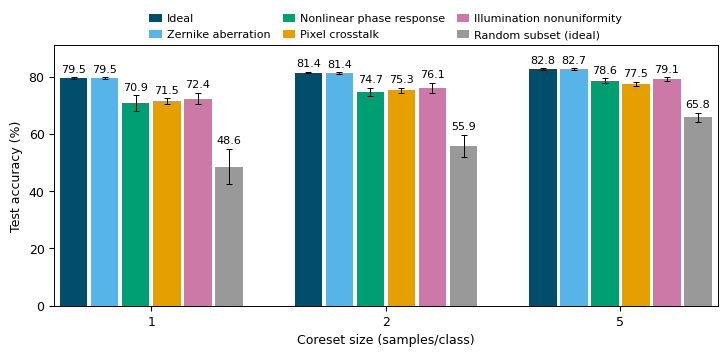

PosixPath('/home/laserthu/user_data/JJJ/release_validation/full_reproduction_20261022_002107/stage/results/SI__reservoir_mismatch__summary.npz')

In [36]:
rm_order = ['ideal', 'zernike', 'nonlinear', 'crosstalk', 'illumination']
rm_names = ['Ideal', 'Zernike aberration', 'Nonlinear phase response',
            'Pixel crosstalk', 'Illumination nonuniformity', 'Random subset (ideal)']
rm_colours = ['#004e6c', '#56b4e9', '#009e73', '#e69f00', '#cc79a7', '#999999']
rm_per_rep = [100*rm_results[k]['accuracy_per_tm'].mean(axis=2)[:, :, 0] for k in rm_order]
rm_per_rep.append(100*rm_results['ideal']['accuracy_per_tm'].mean(axis=2)[:, :, 1])
fig, ax = plt.subplots(figsize=(7.2, 3.5))
centres = np.arange(len(RM_IPCS))*1.02
spacing, width = 0.135, 0.119
for k, (values, label, colour) in enumerate(zip(rm_per_rep, rm_names, rm_colours)):
    mean, sd = values.mean(axis=1), values.std(axis=1, ddof=1)
    x = centres + (k-2.5)*spacing
    ax.bar(x, mean, width, yerr=sd, color=colour, label=label, capsize=2,
           error_kw={'elinewidth': 0.7, 'capthick': 0.7})
    for xp, yp, err in zip(x, mean, sd):
        ax.text(xp, yp+err+1.0, f'{yp:.1f}', ha='center', va='bottom', fontsize=8)
edge = 2.5*spacing + width/2 + 0.025
ax.set(xlim=(centres[0]-edge, centres[-1]+edge), ylim=(0, 91),
       xticks=centres, xticklabels=RM_IPCS, xlabel='Coreset size (samples/class)',
       ylabel='Test accuracy (%)')
ax.tick_params(labelsize=9)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.7)
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.005),
          frameon=False, fontsize=8, handlelength=1.1, handletextpad=0.45,
          columnspacing=1.1, borderaxespad=0)
fig.tight_layout(pad=0.5)
for suffix in ['png', 'svg']:
    if SAVE_FIGURES:
        fig.savefig(flat_result_path(RM_FIGURES / f'reservoir_model_mismatch.{suffix}'), dpi=200, bbox_inches='tight')
plt.show()
save_npz(RM_OUTPUT / 'summary.npz', {
    'mean_percent': np.stack([v.mean(1) for v in rm_per_rep]),
    'sd_percent': np.stack([v.std(1, ddof=1) for v in rm_per_rep]),
    'ipc_values': RM_IPCS, 'labels': rm_names,
    'mean_speckle_correlation': [rm_results[k]['speckle_correlation'].mean() for k in rm_order],
})

### B. Unexpected hardware errors in the programmable ONN — Supplementary Figure 9

See [Exp4_MZI_Adaptive_Retraining.ipynb](Exp4_MZI_Adaptive_Retraining.ipynb), section 6, for the four hardware-error comparisons and Supplementary Figure 9a–d.


## Supplementary Note 6. Comparison with other representative data compression methods


In [44]:
import os, gc, json
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from utils.datasets import load_fmnist, save_npz
from utils.distillation import distill_coreset
from utils.reservoir_onn import tm_ensemble
from utils.plotting import muted_magma
from utils.method_comparison import (
    MethodComparisonConfig, METHODS, LABELS, select_method_lambdas,
    _support, _pm_config, _dm_targets, _evaluate, _save_support,
)

ROOT = Path.cwd()
METHOD_DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
# Batches are computed on demand, avoiding a >11 GiB training-feature cache.
METHOD_CONFIG = MethodComparisonConfig(cache_training_features=False)
METHOD_OUTPUT = ROOT / 'results/SI/method_comparison'
flat_result_directory(METHOD_OUTPUT).mkdir(parents=True, exist_ok=True)
method_data = load_fmnist(ROOT / 'dataset', device=METHOD_DEVICE, download=True)
method_results, method_supports, method_histories = {}, {}, {}
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.linewidth':0.8})


### Shared validation, synthesis and evaluation



In [45]:
def run_one_method(method):
    cfg = METHOD_CONFIG
    x, y = method_data['x_train'], method_data['y_train']
    selected = select_method_lambdas(x, y, cfg, METHOD_OUTPUT / 'validation' / method,
                                     methods=(method,), verbose=False, save_details=SAVE_DETAILS)
    repetitions = cfg.main_repetitions if method in ('random', 'ours') else cfg.baseline_repetitions
    scores = np.empty((len(cfg.ipc_values), repetitions, cfg.test_tm_count))
    for rep in range(repetitions):
        train_seeds = list(range(1000+1000*rep, 1000+1000*rep+cfg.training_tm_count))
        test_seeds = list(range(9000+1000*rep, 9000+1000*rep+cfg.test_tm_count))
        assert set(train_seeds).isdisjoint(test_seeds)
        tms = tm_ensemble(x.shape[1], cfg.output_dim, train_seeds, x.device) if method in ('ours','optical_dm') else None
        means, scales = _dm_targets(x,y,tms,None) if method=='optical_dm' else (None,None)
        supports = {}
        for ipc in cfg.ipc_values:
            if method == 'ours':
                trained = distill_coreset(x,y,tms,_pm_config(cfg,ipc,selected[method,ipc],rep=rep))
                support = trained.x_coreset, trained.y_coreset
                diagnostic = {'loss_history':trained.loss_history, 'source_indices':trained.coreset_indices}
            else:
                support, diagnostic = _support(cfg,method,x,y,ipc,
                    22025+rep if method=='random' else 2025+rep,tms=tms,means=means,scales=scales)
            supports[method,ipc] = support
            if SAVE_DETAILS:
                _save_support(METHOD_OUTPUT/f'supports/{method}_ipc{ipc}_rep{rep}.npz',support,diagnostic,
                    method=method,ipc=ipc,repetition=rep,readout_lambda=selected[method,ipc],
                    training_tm_seeds=train_seeds,test_tm_seeds=test_seeds)
            if rep == 0:
                method_supports[method,ipc] = tuple(v.detach().cpu().numpy() for v in support)
                if 'loss_history' in diagnostic:
                    method_histories[method,ipc] = np.asarray(diagnostic['loss_history'])
        del tms, means, scales
        test_tms = tm_ensemble(x.shape[1],cfg.output_dim,test_seeds,x.device)
        measured = _evaluate(supports,method_data['x_test'],method_data['y_test'],test_tms,beta=selected)
        for j,ipc in enumerate(cfg.ipc_values): scores[j,rep] = measured[method,ipc]
        del supports, test_tms
        gc.collect()
    save_npz(METHOD_OUTPUT/f'{method}.npz',{'accuracy_per_tm':scores,'ipc_values':cfg.ipc_values,
        'ridge_lambda':[selected[method,ipc] for ipc in cfg.ipc_values]})
    print(f'{LABELS[method]} complete.')
    return scores

def show_method_training(method):
    fig, ax = plt.subplots(figsize=(5,2.8),layout='constrained')
    for ipc in METHOD_CONFIG.ipc_values:
        loss = method_histories[method,ipc]
        ax.plot(np.arange(1,len(loss)+1),loss,lw=1,label=f'SPC = {ipc}')
    ax.set(xlabel='Optimization step',ylabel='Training loss',title=LABELS[method])
    ax.spines[['top','right']].set_visible(False)
    ax.legend(frameon=False,fontsize=8)
    plt.show()


### Random subset

Sample distinct real images independently within each class; retain one-hot labels.


In [46]:
method_results['random'] = run_one_method('random')


Random subset complete.


### Pixel-space herding

Select distinct real images by greedy class-wise pixel-mean matching; retain one-hot labels.


In [47]:
method_results['herding'] = run_one_method('herding')


Pixel-space herding complete.


### K-means prototypes

Fit class-wise K-means++ prototypes for at most 40 iterations. At SPC = 1 use the class mean; labels remain one-hot.


In [48]:
method_results['kmeans'] = run_one_method('kmeans')


K-means prototypes complete.


### RBF-KIP

Optimize inputs and targets for 700 Adam updates (learning rate 0.01) using a digital RBF kernel. Its bandwidth is the median of 4,096 sampled positive squared distances, and inner ridge λ = 0.001. Transfer the final support to the ONN for evaluation.


RBF-KIP complete.


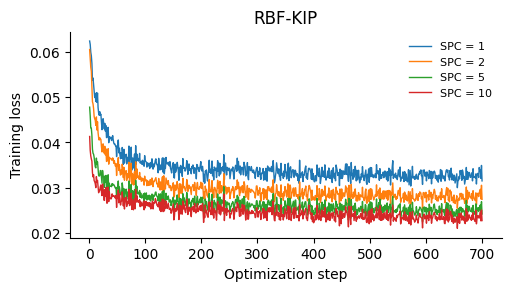

In [49]:
method_results['rbf_kip'] = run_one_method('rbf_kip')
show_method_training('rbf_kip')


### Optical distribution matching

Optimize inputs for 700 Adam updates (learning rate 0.01), matching class-mean optical features. Use 50 TMs, four cyclically selected per update; normalize by each TM’s full-training maximum. One-hot labels remain fixed.


Optical DM complete.


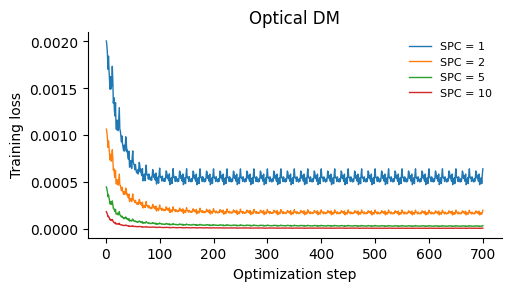

In [50]:
method_results['optical_dm'] = run_one_method('optical_dm')
show_method_training('optical_dm')


### Task-aware distillation (Ours)



Ours complete.


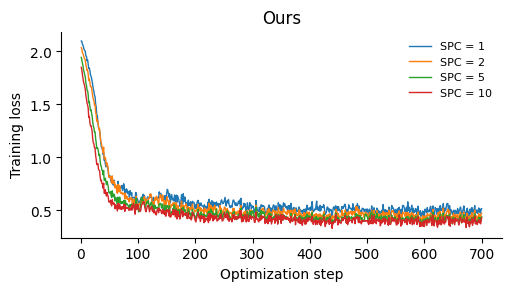

In [51]:
method_results['ours'] = run_one_method('ours')
show_method_training('ours')


### Classification accuracy — Supplementary Table 4



In [52]:
comparison_rows = []
for method in METHODS:
    per_rep = method_results[method].mean(axis=2) * 100
    row = {'Method': LABELS[method]}
    for j,ipc in enumerate(METHOD_CONFIG.ipc_values):
        row[f'SPC = {ipc}'] = f'{per_rep[j].mean():.2f} ± {per_rep[j].std(ddof=1):.2f}'
    comparison_rows.append(row)
method_table = pd.DataFrame(comparison_rows)
display(method_table.style.hide(axis='index'))
method_table.to_csv(flat_result_path(METHOD_OUTPUT/'comparison.csv'),index=False)


Method,SPC = 1,SPC = 2,SPC = 5,SPC = 10
Random subset,48.79 ± 6.28,55.85 ± 3.95,65.84 ± 1.60,71.17 ± 1.27
Pixel-space herding,64.01 ± 0.12,66.09 ± 0.06,69.83 ± 0.07,72.01 ± 0.06
K-means prototypes,68.01 ± 0.08,72.97 ± 0.07,78.82 ± 0.22,79.52 ± 0.25
RBF-KIP,67.11 ± 1.66,73.28 ± 2.56,77.31 ± 0.60,78.79 ± 0.40
Optical DM,67.67 ± 0.08,72.75 ± 0.57,78.17 ± 0.42,79.74 ± 0.24
Ours,79.50 ± 0.34,81.35 ± 0.29,82.75 ± 0.20,83.37 ± 0.14


### Representative training inputs — Supplementary Figure 10

Two classes at SPC = 1, using the first repetition and the same [0,1] colour scale for every method.


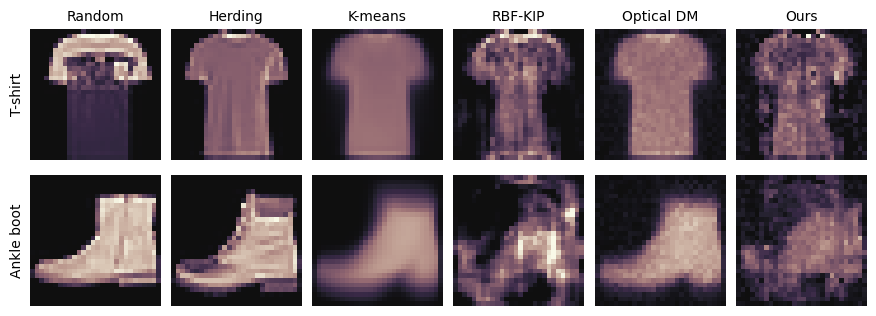

In [53]:
fig, axes = plt.subplots(2,6,figsize=(9,3.2))
short_names = ['Random','Herding','K-means','RBF-KIP','Optical DM','Ours']
for col,method in enumerate(METHODS):
    masks = method_supports[method,1][0].reshape(10,28,28)
    for row,cls in enumerate([0,9]):
        ax = axes[row,col]
        ax.imshow(masks[cls],cmap=muted_magma(),vmin=0,vmax=1,interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([])
        ax.spines[:].set_visible(False)
        if row == 0: ax.set_title(short_names[col],fontsize=10)
axes[0,0].set_ylabel('T-shirt')
axes[1,0].set_ylabel('Ankle boot')
fig.subplots_adjust(wspace=0.08,hspace=0.08,left=0.065,right=0.995,bottom=0.02,top=0.90)
plt.show()


## Supplementary Note 7. Task-tailored synthetic data beyond dataset compression



In [54]:
import os, json
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.datasets import MNIST
from torchvision.transforms import InterpolationMode
from torchvision.transforms.functional import rotate
from utils.datasets import class_balanced_indices, save_npz
from utils.reservoir_onn import random_tm, set_seed

ROOT = Path.cwd()
TASK_DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
TASK_CONFIG = dict(seeds=[2026,2027,2028],lambdas=[0.,.25,.5,.75,1.],
    tm_seed=1000,output_dim=1024,angle=30.,validation_per_class=500,split_seed=4201,
    steps=700,eval_every=50,batch_per_domain=512,lr=.01,inner_beta=1.,
    beta_grid=[.0001,.001,.01,.1,1.,10.,100.],random_per_domain_class=150)
TASK_OUTPUT = ROOT/'results/SI/task_tailored'
flat_result_directory(TASK_OUTPUT).mkdir(parents=True,exist_ok=True)
(flat_result_path(TASK_OUTPUT/'config.json')).write_text(json.dumps(TASK_CONFIG,indent=2))
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32 = False
set_seed(2026)

def task_rotate(x):
    return rotate(x.reshape(-1,1,28,28),TASK_CONFIG['angle'],
        interpolation=InterpolationMode.BILINEAR,expand=False,fill=0).reshape(-1,784)

def task_raw(x):
    return torch.abs(torch.exp(1j*torch.pi*x) @ task_tm).square()

@torch.no_grad()
def task_features(x):
    return torch.cat([task_raw(b) for b in x.split(1024)])

def task_dual(z,y,beta):
    return z.T @ torch.linalg.solve(z@z.T+beta*torch.eye(len(z),device=z.device,dtype=z.dtype),y)

@torch.no_grad()
def task_scores(w,zs,labels):
    return np.array([float((z.to(w.dtype)@w).argmax(1).eq(labels).float().mean()) for z in zs])

@torch.no_grad()
def task_fit(z,y,lam):
    z,y=z.double(),y.double()
    best=-np.inf
    for beta in TASK_CONFIG['beta_grid']:
        w=task_dual(z,y,beta) if len(z)<=1024 else torch.linalg.solve(
            z.T@z+beta*torch.eye(z.shape[1],device=z.device,dtype=z.dtype),z.T@y)
        acc=task_scores(w,task_val_features,task_y_val)
        value=lam*acc[0]+(1-lam)*acc[1]
        if value>best: best,best_w,best_beta=value,w,beta
    return best_w,best_beta

task_dataset=MNIST(ROOT/'dataset',train=True,download=True)
task_x=task_dataset.data.to(TASK_DEVICE).float().reshape(-1,784)/255
task_y=task_dataset.targets.to(TASK_DEVICE)
task_val_ids=class_balanced_indices(task_y,TASK_CONFIG['validation_per_class'],seed=TASK_CONFIG['split_seed'])
task_keep=torch.ones(len(task_y),device=TASK_DEVICE,dtype=torch.bool)
task_keep[task_val_ids]=False
task_train_ids=torch.where(task_keep)[0]
task_x_train,task_y_train=task_x[task_train_ids],task_y[task_train_ids]
task_x_val,task_y_val=task_x[task_val_ids],task_y[task_val_ids]
task_rotated_train=task_rotate(task_x_train)
task_tm=random_tm(784,TASK_CONFIG['output_dim'],TASK_CONFIG['tm_seed'],TASK_DEVICE)
task_train_features=[task_features(q) for q in [task_x_train,task_rotated_train]]
task_scale=max(float(z.max()) for z in task_train_features)
task_train_features=[z/task_scale for z in task_train_features]
task_val_features=[task_features(q)/task_scale for q in [task_x_val,task_rotate(task_x_val)]]
save_npz(TASK_OUTPUT/'split.npz',{'train_ids':task_train_ids,'validation_ids':task_val_ids,
    'tm':task_tm,'normalization':task_scale})
task_models,task_histories,task_endpoints=[],{},{}


### Joint distillation and λ sweep


Joint distillation complete.


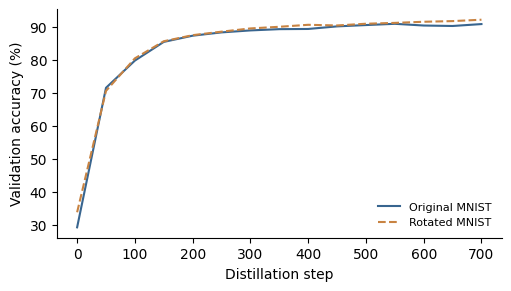

In [55]:
def task_distill(x0,y0,lam,seed):
    x=x0.clone().requires_grad_(); y=y0.clone().requires_grad_()
    logtau=torch.tensor(0.,device=TASK_DEVICE,requires_grad=True)
    optimizer=torch.optim.Adam([x,y,logtau],lr=TASK_CONFIG['lr'])
    generator=torch.Generator(device=TASK_DEVICE).manual_seed(seed+7000)
    best=-np.inf; losses=[]; history=[]
    batch=TASK_CONFIG['batch_per_domain']
    for step in range(TASK_CONFIG['steps']+1):
        if step%TASK_CONFIG['eval_every']==0 or step==TASK_CONFIG['steps']:
            with torch.no_grad():
                w=task_dual(task_raw(x)/task_scale,y,TASK_CONFIG['inner_beta'])
                acc=task_scores(w,task_val_features,task_y_val)
                score=lam*acc[0]+(1-lam)*acc[1]
                history.append([step,*acc])
                if score>best: best,bx,by,best_step=score,x.detach().clone(),y.detach().clone(),step
        if step==TASK_CONFIG['steps']: break
        indices=torch.randint(len(task_y_train),(2*batch,),device=TASK_DEVICE,generator=generator)
        query=torch.cat([task_train_features[0][indices[:batch]],task_train_features[1][indices[batch:]]])
        optimizer.zero_grad()
        w=task_dual(task_raw(x)/task_scale,y,TASK_CONFIG['inner_beta'])
        ce=F.cross_entropy(query@w/logtau.exp(),task_y_train[indices],reduction='none')
        loss=lam*ce[:batch].mean()+(1-lam)*ce[batch:].mean()
        if not torch.isfinite(loss): raise FloatingPointError('Non-finite distillation loss')
        loss.backward(); optimizer.step()
        with torch.no_grad(): x.clamp_(0,1)
        losses.append(float(loss.detach()))
    save_npz(TASK_OUTPUT/f'joint_lambda{lam:g}_seed{seed}.npz',
        {'x':bx,'y':by,'loss':losses,'validation_history':history,'best_step':best_step})
    return bx,by,np.asarray(history)

for seed in TASK_CONFIG['seeds']:
    ids=class_balanced_indices(task_y_train,1,seed=seed)
    generator=torch.Generator(device=TASK_DEVICE).manual_seed(seed+31000)
    rotated_classes=torch.randperm(10,device=TASK_DEVICE,generator=generator)[:5]
    x0=task_x_train[ids].clone(); x0[rotated_classes]=task_rotated_train[ids[rotated_classes]]
    y0=F.one_hot(task_y_train[ids],10).float()
    for lam in TASK_CONFIG['lambdas']:
        sx,sy,history=task_distill(x0,y0,lam,seed)
        w,beta=task_fit(task_raw(sx).detach()/task_scale,sy,lam)
        task_models.append(dict(method='Joint',seed=seed,lam=lam,w=w,beta=beta,n=10))
        task_histories[seed,lam]=history
        if lam in (0.,1.): task_endpoints[seed,lam]=(sx,sy)
print('Joint distillation complete.')
fig,ax=plt.subplots(figsize=(5,2.8),layout='constrained')
history=task_histories[TASK_CONFIG['seeds'][0],.5]
ax.plot(history[:,0],100*history[:,1],color='#38658f',label='Original MNIST')
ax.plot(history[:,0],100*history[:,2],'--',color='#c88342',label='Rotated MNIST')
ax.set(xlabel='Distillation step',ylabel='Validation accuracy (%)')
ax.spines[['top','right']].set_visible(False); ax.legend(frameon=False,fontsize=8)
plt.show()


### Separate distillation and random sampling



In [56]:
for seed in TASK_CONFIG['seeds']:
    xa,ya=task_endpoints[seed,1.]; xb,yb=task_endpoints[seed,0.]
    w,beta=task_fit(task_raw(torch.cat([xa,xb])).detach()/task_scale,torch.cat([ya,yb]),.5)
    task_models.append(dict(method='Separate',seed=seed,lam=.5,w=w,beta=beta,n=20))
    count=TASK_CONFIG['random_per_domain_class']
    ids=class_balanced_indices(task_y_train,2*count,seed=5201+seed-2026).reshape(10,2*count)
    a,b=ids[:,:count].flatten(),ids[:,count:].flatten()
    z=torch.cat([task_train_features[0][a],task_train_features[1][b]])
    labels=torch.cat([task_y_train[a],task_y_train[b]])
    w,beta=task_fit(z,F.one_hot(labels,10).float(),.5)
    task_models.append(dict(method='Random',seed=seed,lam=.5,w=w,beta=beta,n=len(z)))
print('Separate distillation and Random complete.')


Separate distillation and Random complete.


### Shared-readout test evaluation



In [57]:
task_test=MNIST(ROOT/'dataset',train=False,download=True)
task_x_test=task_test.data.to(TASK_DEVICE).float().reshape(-1,784)/255
task_y_test=task_test.targets.to(TASK_DEVICE)
task_test_features=[task_features(q)/task_scale for q in [task_x_test,task_rotate(task_x_test)]]
task_results=[]
for model in task_models:
    acc=task_scores(model['w'],task_test_features,task_y_test)
    task_results.append({k:v for k,v in model.items() if k!='w'} | {
        'original':float(acc[0]),'rotated':float(acc[1]),'mean':float(acc.mean())})
    save_npz(TASK_OUTPUT/f"readout_{model['method']}_{model['lam']:g}_{model['seed']}.npz",{'w':model['w']})
(flat_result_path(TASK_OUTPUT/'results.json')).write_text(json.dumps(task_results,indent=2))
print('Test evaluation complete.')


Test evaluation complete.


### Domain weighting — Supplementary Figure 11a


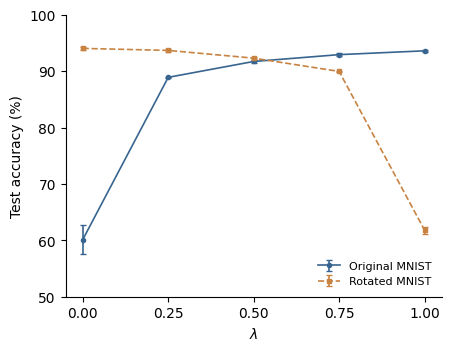

In [58]:
fig,ax=plt.subplots(figsize=(4.4,3.4),layout='constrained')
for domain,label,color,marker,style in [('original','Original MNIST','#38658f','o','-'),
                                       ('rotated','Rotated MNIST','#c88342','s','--')]:
    values=np.array([[r[domain]*100 for r in task_results if r['method']=='Joint' and r['lam']==lam]
                     for lam in TASK_CONFIG['lambdas']])
    ax.errorbar(TASK_CONFIG['lambdas'],values.mean(1),yerr=values.std(1,ddof=1),
                label=label,color=color,marker=marker,ls=style,lw=1.2,ms=3,capsize=2)
ax.set(xlabel=r'$\lambda$',ylabel='Test accuracy (%)',ylim=(50,100),xticks=TASK_CONFIG['lambdas'])
ax.spines[['top','right']].set_visible(False); ax.legend(loc='lower right',fontsize=8,frameon=False)
plt.show()


### Training-set construction — Supplementary Figure 11b


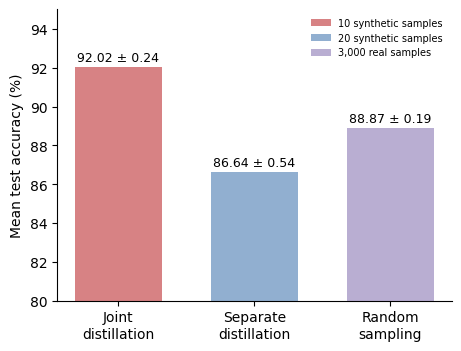

In [59]:
fig,ax=plt.subplots(figsize=(4.5,3.4),layout='constrained')
for j,(method,color,label) in enumerate(zip(['Joint','Separate','Random'],
        ['#d78284','#91afd0','#b9aed2'],['10 synthetic samples','20 synthetic samples','3,000 real samples'])):
    values=np.array([r['mean']*100 for r in task_results if r['method']==method and r['lam']==.5])
    mean,sd=values.mean(),values.std(ddof=1)
    ax.bar(j,mean,width=.64,color=color,label=label)
    ax.text(j,mean+.3,f'{mean:.2f} ± {sd:.2f}',ha='center',fontsize=9)
ax.set(xticks=[0,1,2],xticklabels=['Joint\ndistillation','Separate\ndistillation','Random\nsampling'],
       ylabel='Mean test accuracy (%)',ylim=(80,95))
ax.spines[['top','right']].set_visible(False);ax.legend(loc='upper right',frameon=False,fontsize=7)
plt.show()


## Representative performance and sample efficiency of synthetic coresets — Supplementary Table 3



In [60]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from utils.classification_sample_efficiency import run_classification_search
from utils.regression_sample_efficiency import run_regression_task, _narma_origins, regression_inputs
from utils.forecasting import ReservoirReadoutEnsemble, autonomous_rollout, quantize_mask, r2_per_tm
from utils.reservoir_onn import tm_ensemble

ROOT=Path.cwd()
SUMMARY_DEVICE='cuda:0' if torch.cuda.is_available() else 'cpu'
SUMMARY_OUTPUT=ROOT/'results/SI/representative_summary'
flat_result_directory(SUMMARY_OUTPUT).mkdir(parents=True,exist_ok=True)
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32=False

classification_search=run_classification_search(ROOT,device=SUMMARY_DEVICE,recompute=True,
    output_dir=SUMMARY_OUTPUT/'classification',cora_sampling='uniform')
regression_search={task:run_regression_task(ROOT,task,device=SUMMARY_DEVICE,recompute=True,
    output_dir=SUMMARY_OUTPUT/'regression') for task in ['ccpp','narma10']}
assert regression_search['narma10']['evaluation_protocol']=='independent_tm_feedback'

def summary_npz(relative):
    with np.load(flat_result_path(ROOT/relative),allow_pickle=False) as f:
        return {k:f[k].copy() for k in f.files}

def first_crossing_gains(result,regression=False):
    # Read recorded individual targets and complete evaluated curves, not a rounded gain.
    target_key='experimental_r2' if regression else 'experimental_accuracy'
    budget_key='candidate_size' if regression else 'candidate_ipc'
    score_key='mean_r2' if regression else 'mean_accuracy'
    denominator=result['config']['size' if regression else 'ipc']
    curves={c['rep']:c for c in result['curves']}
    matched={}
    for match in result['matches']:
        curve=curves[match['rep']]
        budget=np.asarray(curve[budget_key],dtype=float)
        score=np.asarray(curve[score_key],dtype=float)
        hits=budget[score>=match[target_key]]
        if not len(hits): raise ValueError('Random search did not reach a measured target.')
        gain=float(hits.min()/denominator)
        matched[match['rep'],str(match['acquisition'])]=gain
    values=[matched[int(rep),str(acquisition)] for rep,acquisition
            in zip(result['source_reps'],result['acquisitions'])]
    return np.asarray(values)

def mean_sd(values,scale=1.,digits=2):
    values=np.asarray(values,dtype=float).reshape(-1)*scale
    assert len(values)>1 and np.isfinite(values).all()
    return f'{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}'


AG News: rep 1/5, 20 candidate budgets; matched random/class = [100, 75]


AG News: rep 2/5, 25 candidate budgets; matched random/class = [125, 105]


AG News: rep 3/5, 25 candidate budgets; matched random/class = [105, 95]


AG News: rep 4/5, 25 candidate budgets; matched random/class = [110, 120]


AG News: rep 5/5, 25 candidate budgets; matched random/class = [125, 100]


Cora: rep 1/5, 25 candidate budgets; matched random/class = [44, 50]


... (425 outputs left out)

narma10 rep=5 phase=fine size=112 random_R2=0.8987724


narma10 rep=5 phase=fine size=114 random_R2=0.9006914


narma10 rep=5 phase=fine size=116 random_R2=0.9015496


narma10 rep=5 phase=fine size=118 random_R2=0.9032086


### NARMA10 full-data reference



In [61]:
@torch.no_grad()
def summary_ccpp_full():
    from utils.regression import evaluate_regression, SUPPORT_ONLY_TRAIN_CALIBRATION
    data=regression_inputs(ROOT,'ccpp')
    tensor=lambda value:torch.as_tensor(value,dtype=torch.float32,device=SUMMARY_DEVICE)
    scores=[]
    for rep,seeds in enumerate(data['test_tm_seeds']):
        tms=tm_ensemble(64,1024,seeds,SUMMARY_DEVICE)
        x=torch.cat([tensor(data['x_train_mask_flat_per_rep'][rep]),tensor(data['x_validation_mask_flat_per_rep'][rep])])
        y=torch.cat([tensor(data['y_train_standardized_per_rep'][rep]),tensor(data['y_validation_standardized_per_rep'][rep])])
        output=evaluate_regression(x,y,tensor(data['x_test_mask_flat_per_rep'][rep]),
            tensor(data['y_test_standardized_per_rep'][rep]),tms,float(data['full_beta'][rep]),
            return_predictions=True,optical_intensity_normalization_policy=SUPPORT_ONLY_TRAIN_CALIBRATION)
        prediction=output['prediction_per_tm'].astype(float)*data['y_std_per_rep'][rep]+data['y_mean_per_rep'][rep]
        truth=data['y_test_raw_per_rep'][rep].astype(float)
        per_tm=1-np.square(prediction-truth[None]).sum(axis=(1,2))/np.square(truth-truth.mean()).sum()
        scores.append(per_tm.mean())
        del tms
    return np.asarray(scores)

@torch.no_grad()
def summary_narma_full():
    data=regression_inputs(ROOT,'narma10')
    origins=_narma_origins(ROOT,data)
    tensor=lambda value:torch.as_tensor(value,dtype=torch.float32,device=SUMMARY_DEVICE)
    x=quantize_mask(tensor(data['train_masks']))
    y=tensor(data['y_train_scaled'])
    prep=dict(x_train=x,x_lower=data['x_native_lower'],x_scale=data['x_native_scale'],
        y_mean=data['y_mean'],y_std=data['y_std'],
        projection_matrix=tensor(data['projection_matrix']),projection_lower=tensor(data['projection_lower']),
        projection_scale=tensor(data['projection_scale']))
    per_rep=[]
    for rep,seeds in enumerate(data['test_tm_seeds']):
        # Device chunks bound memory while preserving one independent trajectory per TM.
        by_origin=[[] for _ in origins['starts']]
        for begin in range(0,len(seeds),5):
            tms=tm_ensemble(64,1024,seeds[begin:begin+5],SUMMARY_DEVICE)
            model=ReservoirReadoutEnsemble(x,y,float(data['full_beta'][rep]),tms)
            for j,start in enumerate(origins['starts']):
                prediction=autonomous_rollout(model,data['drive_full'].reshape(-1),
                    origins['state'],int(start),200,prep,quantize8=True)
                by_origin[j].extend(r2_per_tm(prediction,origins['truth'][j]))
            del model,tms
        per_rep.append(np.asarray(by_origin))
    scores=np.asarray(per_rep)
    np.savez_compressed(flat_result_path(SUMMARY_OUTPUT/'narma10_full_independent.npz'),r2_by_rep_origin_tm=scores)
    return scores.mean(axis=(1,2))

summary_narma_scores=summary_narma_full()
print('NARMA10 full-data evaluation complete.')


NARMA10 full-data evaluation complete.


### Representative results



In [62]:
summary_rows=[]
def add_summary(name,size,training_size,full,coreset,random,gain,classification=True):
    scale,digits=(100,2) if classification else (1,4)
    summary_rows.append({'Dataset':name,'Coreset size':size,
        'Compression factor':f'{training_size/size:,.2f}×',
        'Full-data (Sim.)':'—' if full is None else mean_sd(full,scale,digits),
        'Synthetic coreset':mean_sd(coreset,scale,digits),
        'Random subset':mean_sd(random,scale,digits),
        'Sample-efficiency gain':gain if isinstance(gain,str) else '('+mean_sd(gain)+')×'})

exp=summary_npz('results/experimental/fmnist_experiment.npz')
sim=summary_npz('results/simulation/fmnist/fmnist_sweep.npz')
eff=summary_npz('results/experimental/fmnist_sample_efficiency.npz')
j=list(exp['ipc_values']).index(1); k=list(eff['coreset_ipc']).index(1)
assert not np.any(eff['is_lower_bound'][:,k])
fmnist_gain=eff['matched_random_ipc'][:,k]/eff['coreset_ipc'][k]
add_summary('Fashion-MNIST (reservoir-type ONN)',10,60000,sim['full_accuracy'],
    exp['x_plus_y_accuracy'][:,j],exp['random_accuracy'][:,j],fmnist_gain)

mzi=json.loads((flat_result_path(ROOT/'results/simulation/mzi/main.json')).read_text())
mzi_ablation=json.loads((flat_result_path(ROOT/'results/simulation/mzi/ablations/results.json')).read_text())
mzi_extension=json.loads((flat_result_path(ROOT/'results/simulation/mzi/random_extension.json')).read_text())
mzi_coreset=np.asarray(mzi['static']['dd80']['per_chip'])
hit=min(int(step) for step,row in mzi_extension['curves'].items()
        if np.mean(row['per_chip'])>=mzi_coreset.mean())
mzi_gain=hit*10/mzi_extension['DD_input_presentations']
add_summary('Fashion-MNIST (programmable ONN)',80,55000,None,mzi_coreset/100,
    np.asarray(mzi_ablation['random_K8']['per_chip'])/100,f'{mzi_gain:g}×')

for task,ipc,classes,name in [('agnews',5,4,'AG News'),('cora',2,7,'Cora'),('uci_har',5,6,'UCI-HAR')]:
    exp=summary_npz(f'results/experimental/{task}_experiment.npz')
    sim=summary_npz(f'results/simulation/multimodal/{task}_sweep.npz')
    j=list(exp['size_values']).index(ipc)
    full=sim['full_accuracy_per_tm']
    if full.ndim==2: full=full.mean(axis=1)
    result=classification_search[task]
    add_summary(name,ipc*classes,result['train_size'],full,exp['coreset_accuracy'][:,j],
        exp['random_accuracy'][:,j],first_crossing_gains(result))

for task,size,name in [('ccpp',2,'CCPP'),('narma10',24,'NARMA10')]:
    exp=summary_npz(f'results/experimental/{task}_experiment.npz')
    j=list(exp['support_sizes']).index(size)
    result=regression_search[task]
    full=(summary_ccpp_full()
          if task=='ccpp' else summary_narma_scores)
    add_summary(name,size,result['train_size'],full,exp['coreset_r2'][:,j],exp['random_r2'][:,j],
        first_crossing_gains(result,regression=True),classification=False)
representative_table=pd.DataFrame(summary_rows)
display(representative_table.style.hide(axis='index'))
representative_table.to_csv(flat_result_path(SUMMARY_OUTPUT/'representative_performance.csv'),index=False)


Dataset,Coreset size,Compression factor,Full-data (Sim.),Synthetic coreset,Random subset,Sample-efficiency gain
Fashion-MNIST (reservoir-type ONN),10,"6,000.00×",85.30 ± 0.29,79.68 ± 0.62,48.73 ± 5.94,(86.11 ± 15.96)×
Fashion-MNIST (programmable ONN),80,687.50×,—,84.39 ± 0.37,75.71 ± 2.53,50×
AG News,20,"5,798.95×",85.53 ± 0.20,76.86 ± 1.24,39.96 ± 1.37,(21.20 ± 3.05)×
Cora,14,116.00×,88.47 ± 0.03,83.30 ± 1.74,44.56 ± 3.48,(25.70 ± 6.96)×
UCI-HAR,30,196.27×,84.41 ± 0.58,72.88 ± 1.75,56.05 ± 2.40,(19.70 ± 4.30)×
CCPP,2,"3,048.00×",0.9442 ± 0.0029,0.8968 ± 0.0071,0.2839 ± 0.2425,(22.70 ± 9.51)×
NARMA10,24,250.00×,0.9887 ± 0.0001,0.8567 ± 0.0345,0.5826 ± 0.1920,(3.55 ± 0.80)×
